# 7. Porovnanie modelov

Všetky modely sú hodnotené na rovnakých 10 deleniach na trénovacie a testovacie dáta.

Referenčný model **najčastejšia trieda** vždy predpovedá triedu, ktorá je v trénovacích
dátach najčastejšia. Ukazuje, akú presnosť dosiahne model, ktorý sa nič nenaučil.

Metriky na testovacích dátach:
- **presnosť** (*accuracy*) – koľko % testovacích klipov model zaradil správne,
- **správne &lt;trieda&gt;** (*recall*) – koľko % klipov danej triedy model zaradil správne.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from har.config import INDEX_FILE, RESULTS_DIR
from har.evaluation import evaluate_majority, load_predictions, split_scores, summary

df = pd.read_csv(INDEX_FILE)

MODELS = {                                  # súbor v results/ -> názov v tabuľke
    "cnn_svm": "CNN-SVM (ResNet18)",
    "cnn_lstm": "CNN-LSTM (ResNet18)",
    "video_cnn_svm": "R(2+1)D + SVM",
    "video_lstm": "R(2+1)D + LSTM",
    "video_finetune": "R(2+1)D doladená",
}

predictions = {"Najčastejšia trieda": evaluate_majority(df)}
for file, name in MODELS.items():
    if (Path(RESULTS_DIR) / f"{file}.csv").exists():
        predictions[name] = load_predictions(file)
    else:
        print(f"chýba {RESULTS_DIR}/{file}.csv – najprv spustite príslušný notebook")

chýba results/video_finetune.csv – najprv spustite príslušný notebook


## Tabuľka výsledkov

Priemer ± smerodajná odchýlka cez 10 delení.

In [2]:
pd.concat([summary(pred, name) for name, pred in predictions.items()])

,presnosť (accuracy),správne eat (recall),správne clap (recall)
Najčastejšia trieda,43 % ± 9 %,40 % ± 52 %,60 % ± 52 %
CNN-SVM (ResNet18),87 % ± 7 %,93 % ± 6 %,82 % ± 11 %
CNN-LSTM (ResNet18),86 % ± 8 %,94 % ± 4 %,79 % ± 16 %
R(2+1)D + SVM,94 % ± 3 %,98 % ± 4 %,91 % ± 5 %
R(2+1)D + LSTM,91 % ± 4 %,99 % ± 3 %,86 % ± 8 %


## Presnosť modelov

Priemerná presnosť cez 10 delení, čiarka = smerodajná odchýlka.

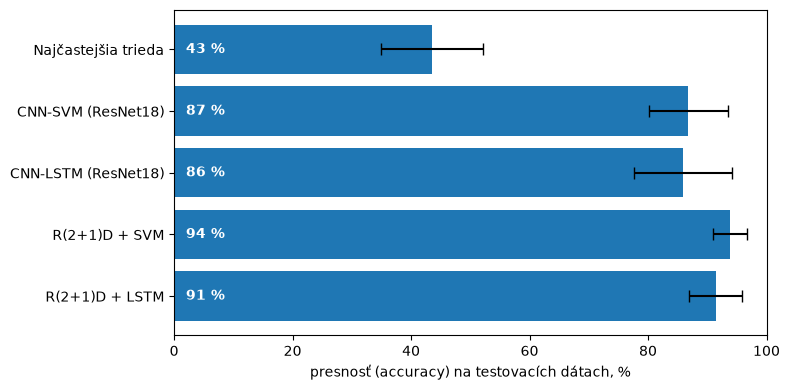

In [3]:
names = list(predictions)
accuracy = [split_scores(pred)["presnosť (accuracy)"] for pred in predictions.values()]
means = [a.mean() for a in accuracy]

fig, ax = plt.subplots(figsize=(8, 0.6 * len(names) + 1))
ax.barh(names, means, xerr=[a.std() for a in accuracy], capsize=4)
for i, m in enumerate(means):
    ax.text(2, i, f"{m:.0f} %", va="center", color="white", fontweight="bold")
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.set_xlabel("presnosť (accuracy) na testovacích dátach, %")
plt.tight_layout()
plt.show()